## React Agent Architecture

#### Base

In [1]:
from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START, END
from langgraph.graph.message import add_messages

import os
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
from typing import Annotated
class State(TypedDict):
    messages:Annotated[list, add_messages]

In [3]:
from langchain.chat_models import init_chat_model

# llm = init_chat_model("google_genai:gemini-2.5-flash-lite")
llm = init_chat_model("groq:qwen/qwen3.8-27b")
llm.profile

#### Tavily Search Tool

In [4]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

#### Custom Tool

In [6]:
def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args :
    a (int): first int
    b (int): second int

    Returns:
    int: output int

    """
    return a*b

#### Bind All Tools with llm

In [7]:
tools = [tool, multiply]

llm_with_tool=llm.bind_tools(tools)

#### StateGraph

In [12]:
## Stategraph
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

In [13]:
builder = StateGraph(State)

In [14]:
def tool_calling_llm(state:State):
    return{ "messages": [llm_with_tool.invoke(state["messages"])]}

##### Here the changes are made

In [15]:
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm",tools_condition)
builder.add_edge("tools","tool_calling_llm")                              # tools output goes back to llm
builder.add_edge("tool_calling_llm",END)

graph = builder.compile()

#### visualize the graph

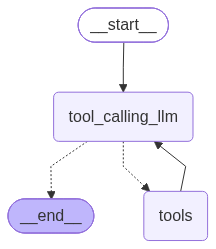

In [16]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

### Test
- and we get output in expected way

In [17]:
response=graph. invoke({"messages":"Give me the latest ai news and then multiply 5 by 2 and then give me latest new about ai jobs"})
for m in response['messages' ] :
    m.pretty_print()

================================ Human Message =================================

Give me the latest ai news and then multiply 5 by 2 and then give me latest new about ai jobs
================================== Ai Message ==================================

I'll help you with all three tasks. Let me search for the latest AI news and calculate the multiplication.
Tool Calls:
  tavily_search (p7wy3bjrd)
 Call ID: p7wy3bjrd
  Args:
    query: latest AI news
    time_range: None
    topic: None
  tavily_search (msg0rak91)
 Call ID: msg0rak91
  Args:
    query: latest news about AI jobs
    time_range: None
    topic: None
  multiply (dydf00082)
 Call ID: dydf00082
  Args:
    a: 5
    b: 2
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.crescendo.ai/news/latest-ai-news-and-updates", "title": "The Latest AI News and Bre